# Exercise 4 ? CNN Width and Depth Experiments

## Objectives
Compare how convolutional width (filters per layer) and depth (number of convolutional layers) affect CIFAR-10 validation performance and trainable parameter count. This notebook contains six completed experiments and their measured results.

**Execution status:** All six experiments completed for 20 epochs. Saved outputs include the per-epoch metrics, comparison table, and plots. Checkpoints and histories are stored in `artifacts/exercise_4/`. The official test split was not loaded or used.

## 1. Introduction: CNN width and depth
**Width** is the number of feature maps (filters) learned at each convolutional layer. Wider layers can represent more patterns, at the cost of more parameters and computation. **Depth** is the number of stacked convolutional layers. Deeper stacks can compose simple features into more complex ones, while adding parameters and optimization difficulty.

The width study keeps the two-convolution baseline structure and changes its channels: 16/32, 32/64, and 64/128. The depth study holds each convolution at 32 filters and compares one, two, and three convolutional layers. All comparisons use the same training data split and optimization configuration; validation metrics are used for comparison.


## 2. Imports and reproducibility
Use the existing project `.venv` and local dataset. Seeds are reset for each experiment so model initialization and the shuffled training order are repeatable.

In [1]:
import json
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from tqdm.notebook import tqdm

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
set_seed()

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_DIR = PROJECT_ROOT / "data"
ARTIFACT_DIR = PROJECT_ROOT / "artifacts" / "exercise_4"
MODEL_DIR = ARTIFACT_DIR / "models"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Project root:", PROJECT_ROOT)
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


Project root: D:\AI ML\AI-ML-assessment-cifar10-project
Device: cuda
GPU: NVIDIA GeForce RTX 3050 Laptop GPU


## 3. Dataset loading and preprocessing
Use the same CIFAR-10 tensor conversion and channel normalization as Exercise 2. `download=False` prevents another dataset download. Only the official training split is loaded here; the official test split is intentionally excluded.

In [2]:
CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD = (0.2470, 0.2435, 0.2616)
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
])
train_val_dataset = datasets.CIFAR10(
    root=str(DATA_DIR), train=True, download=False, transform=transform
)
assert len(train_val_dataset) == 50_000
print("Loaded training examples:", len(train_val_dataset))
print("Classes:", train_val_dataset.classes)


Loaded training examples: 50000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


## 4. Reproducible 45,000/5,000 training-validation split
The split uses the same seed and seeded `randperm` strategy as Exercise 2. Both subsets come exclusively from CIFAR-10's 50,000 official training images.

In [3]:
split_indices = torch.randperm(
    len(train_val_dataset), generator=torch.Generator().manual_seed(SEED)
).tolist()
train_dataset = Subset(train_val_dataset, split_indices[:45_000])
val_dataset = Subset(train_val_dataset, split_indices[45_000:])
assert len(train_dataset) == 45_000 and len(val_dataset) == 5_000
print(f"Training: {len(train_dataset):,}; validation: {len(val_dataset):,}")
print("Official test data remain unused in Exercise 4.")


Training: 45,000; validation: 5,000
Official test data remain unused in Exercise 4.


## 5. Training configuration and data loaders
Match the Exercise 2 setup for a fair comparison: batch size 64, 20 epochs, Adam, and learning rate `1e-3`. Batch size is configurable here, but comparisons should use the same settings for every run. The training loader receives a fresh generator with the fixed seed for each experiment.

In [4]:
BATCH_SIZE = 64
EPOCHS = 20
LEARNING_RATE = 1e-3
NUM_WORKERS = 0

loader_args = {
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "pin_memory": DEVICE.type == "cuda",
}
def make_train_loader():
    generator = torch.Generator().manual_seed(SEED)
    return DataLoader(train_dataset, shuffle=True, generator=generator, **loader_args)
val_loader = DataLoader(val_dataset, shuffle=False, **loader_args)


## 6. CNN architecture definitions
The width models use the Exercise 2 layout: two 3×3 convolutions, ReLU, and 2×2 max pooling after each convolution, followed by a ten-class linear layer. The depth models use 32 filters in every convolution and max pooling after each one. Adaptive average pooling gives each depth model the same 4×4 classifier input size; it has no trainable parameters. Each model has a final linear classifier in addition to the stated number of convolutional layers.

In [5]:
class WidthCNN(nn.Module):
    def __init__(self, first_filters, second_filters):
        super().__init__()
        self.conv1 = nn.Conv2d(3, first_filters, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(first_filters, second_filters, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2)
        self.fc = nn.Linear(second_filters * 8 * 8, 10)
    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))  # Halve the spatial size: 32 to 16
        x = self.pool(F.relu(self.conv2(x)))  # Halve the spatial size: 16 to 8
        return self.fc(torch.flatten(x, 1))

class DepthCNN(nn.Module):
    def __init__(self, conv_layers, filters=32):
        super().__init__()
        if conv_layers not in (1, 2, 3):
            raise ValueError("conv_layers must be 1, 2, or 3")
        layers = []
        in_channels = 3
        for _ in range(conv_layers):
            layers.append(nn.Conv2d(in_channels, filters, kernel_size=3, padding=1))
            in_channels = filters
        self.convs = nn.ModuleList(layers)
        self.pool = nn.MaxPool2d(2)
        self.adaptive_pool = nn.AdaptiveAvgPool2d((4, 4))
        self.fc = nn.Linear(filters * 4 * 4, 10)
    def forward(self, x):
        for conv in self.convs:
            x = self.pool(F.relu(conv(x)))
        x = self.adaptive_pool(x)
        return self.fc(torch.flatten(x, 1))

def build_model(spec):
    if spec["group"] == "width":
        return WidthCNN(spec["first_filters"], spec["second_filters"])
    return DepthCNN(spec["conv_layers"], filters=32)

def count_trainable_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


## 7. Width experiments
Run the same two-convolution topology at three channel widths. The baseline-width architecture (32 then 64 filters) matches Exercise 2.

In [6]:
WIDTH_EXPERIMENTS = [
    {"name": "width_narrow_16_32", "group": "width", "first_filters": 16, "second_filters": 32, "conv_layers": 2},
    {"name": "width_baseline_32_64", "group": "width", "first_filters": 32, "second_filters": 64, "conv_layers": 2},
    {"name": "width_wide_64_128", "group": "width", "first_filters": 64, "second_filters": 128, "conv_layers": 2},
]
for spec in WIDTH_EXPERIMENTS:
    print(spec["name"], "filters:", spec["first_filters"], "→", spec["second_filters"])


width_narrow_16_32 filters: 16 → 32
width_baseline_32_64 filters: 32 → 64
width_wide_64_128 filters: 64 → 128


## 8. Depth experiments
Keep every convolution at 32 filters while changing only the number of convolutional layers. Shallow, medium, and deep refer to convolutional depth; all models also include the same type of linear classification head.

In [7]:
DEPTH_EXPERIMENTS = [
    {"name": "depth_shallow_1conv_32", "group": "depth", "conv_layers": 1},
    {"name": "depth_medium_2conv_32", "group": "depth", "conv_layers": 2},
    {"name": "depth_deep_3conv_32", "group": "depth", "conv_layers": 3},
]
EXPERIMENTS = WIDTH_EXPERIMENTS + DEPTH_EXPERIMENTS
print("Planned model runs:", len(EXPERIMENTS))


Planned model runs: 6


## 9. Training and validation evaluation
Train each model independently with CrossEntropyLoss and Adam. Record sample-weighted train and validation loss and accuracy on every epoch. The validation set may be used to compare models; the test set is not loaded or consulted. A CUDA out-of-memory error stops the run rather than changing batch size or retrying.

In [8]:
criterion = nn.CrossEntropyLoss()
EXPERIMENT_LABELS = {
    "width_narrow_16_32": "Narrow CNN",
    "width_baseline_32_64": "Baseline-width CNN",
    "width_wide_64_128": "Wide CNN",
    "depth_shallow_1conv_32": "Shallow CNN",
    "depth_medium_2conv_32": "Medium CNN",
    "depth_deep_3conv_32": "Deep CNN",
}

def epoch_metrics(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    loss_sum = correct = sample_count = 0
    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        for images, labels in tqdm(loader, desc=("Train" if training else "Validation"), position=1, leave=False):
            try:
                images = images.to(DEVICE, non_blocking=True)
                labels = labels.to(DEVICE, non_blocking=True)
                if training:
                    optimizer.zero_grad(set_to_none=True)
                logits = model(images)
                loss = criterion(logits, labels)
                if training:
                    loss.backward()
                    optimizer.step()
                n = labels.size(0)
                sample_count += n
                loss_sum += loss.item() * n
                correct += (logits.argmax(1) == labels).sum().item()
            except torch.cuda.OutOfMemoryError as exc:
                if training:
                    optimizer.zero_grad(set_to_none=True)
                if torch.cuda.is_available():
                    torch.cuda.empty_cache()
                raise RuntimeError(
                    "CUDA out of memory. Run stopped without retry. Reduce BATCH_SIZE, recreate the model and optimizer, then restart that experiment."
                ) from exc
    return loss_sum / sample_count, correct / sample_count

def run_experiment(spec):
    label = EXPERIMENT_LABELS[spec["name"]]
    print(f"\n{label}\n", flush=True)
    set_seed(SEED)
    model = build_model(spec).to(DEVICE)
    params = count_trainable_parameters(model)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    train_loader = make_train_loader()
    history = {k: [] for k in ("train_loss", "train_accuracy", "val_loss", "val_accuracy")}
    history["epoch_seconds"] = []
    best_val_accuracy = -1.0
    best_epoch = None
    best_state = None
    start = time.perf_counter()
    epoch_progress = tqdm(range(1, EPOCHS + 1), desc=label, unit="epoch", position=0)
    for epoch in epoch_progress:
        epoch_start = time.perf_counter()
        train_loss, train_accuracy = epoch_metrics(model, train_loader, optimizer)
        val_loss, val_accuracy = epoch_metrics(model, val_loader)
        epoch_seconds = time.perf_counter() - epoch_start
        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_accuracy)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_accuracy)
        history["epoch_seconds"].append(epoch_seconds)
        if val_accuracy > best_val_accuracy:
            best_val_accuracy, best_epoch = val_accuracy, epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        epoch_progress.set_postfix({
            "epoch": f"{epoch}/{EPOCHS}",
            "train_loss": f"{train_loss:.4f}",
            "train_acc": f"{train_accuracy:.4f}",
            "val_loss": f"{val_loss:.4f}",
            "val_acc": f"{val_accuracy:.4f}",
            "best_val": f"{best_val_accuracy:.4f}",
            "epoch_s": f"{epoch_seconds:.1f}",
        }, refresh=True)
        print(
            f"{label} | epoch {epoch}/{EPOCHS} | train loss {train_loss:.4f}, "
            f"train accuracy {train_accuracy:.4f} | val loss {val_loss:.4f}, "
            f"val accuracy {val_accuracy:.4f} | {epoch_seconds:.1f}s",
            flush=True,
        )
    elapsed = time.perf_counter() - start
    ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
    MODEL_DIR.mkdir(parents=True, exist_ok=True)
    torch.save({"model_state_dict": model.cpu().state_dict(), "spec": spec, "seed": SEED}, MODEL_DIR / f"{spec['name']}_final.pth")
    torch.save({"model_state_dict": best_state, "spec": spec, "seed": SEED, "best_epoch": best_epoch}, MODEL_DIR / f"{spec['name']}_best_validation.pth")
    with (ARTIFACT_DIR / f"{spec['name']}_history.json").open("w", encoding="utf-8") as f:
        json.dump(history, f, indent=2)
    model.to(DEVICE)
    print(f"{label}: best validation accuracy {best_val_accuracy:.4f} at epoch {best_epoch}/{EPOCHS}.", flush=True)
    return {
        "name": spec["name"], "display_name": label, "group": spec["group"], "conv_layers": spec["conv_layers"],
        "filters": (spec.get("first_filters"), spec.get("second_filters")) if spec["group"] == "width" else (32,) * spec["conv_layers"],
        "trainable_parameters": params, "best_epoch": best_epoch,
        "best_val_accuracy": best_val_accuracy, "final_val_accuracy": history["val_accuracy"][-1],
        "training_seconds": elapsed, "history": history,
    }


## 10. Run experiments and collect results

The saved output below records all six completed runs, with 20 epochs per configuration. This code cell starts the six training runs again if executed.

In [9]:
experiment_results = []
for experiment_spec in EXPERIMENTS:
    experiment_results.append(run_experiment(experiment_spec))

comparison_rows = [
    {k: result[k] for k in ("name", "display_name", "group", "conv_layers", "filters", "trainable_parameters", "best_epoch", "best_val_accuracy", "final_val_accuracy", "training_seconds")}
    for result in experiment_results
]
comparison = pd.DataFrame(comparison_rows)
comparison = comparison.sort_values(["group", "name"]).reset_index(drop=True)
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
comparison.to_csv(ARTIFACT_DIR / "experiment_comparison.csv", index=False)
with (ARTIFACT_DIR / "experiment_results.json").open("w", encoding="utf-8") as f:
    json.dump(comparison_rows, f, indent=2)
comparison



Narrow CNN


Narrow CNN:   0%|          | 0/20 [00:00<?, ?epoch/s]

Train:   0%|          | 0/704 [00:00<?, ?it/s]

Validation:   0%|          | 0/79 [00:00<?, ?it/s]

Narrow CNN | epoch 1/20 | train loss 1.4052, train accuracy 0.5038 | val loss 1.1907, val accuracy 0.5730 | 10.0s


Train:   0%|          | 0/704 [00:00<?, ?it/s]

... (369 outputs left out)

Validation:   0%|          | 0/79 [00:00<?, ?it/s]

Deep CNN | epoch 20/20 | train loss 0.5157, train accuracy 0.8202 | val loss 0.8485, val accuracy 0.7158 | 12.5s


Deep CNN: best validation accuracy 0.7330 at epoch 17/20.


,name,display_name,group,conv_layers,filters,trainable_parameters,best_epoch,best_val_accuracy,final_val_accuracy,training_seconds
0,depth_deep_3conv_32,Deep CNN,depth,3,"(32, 32, 32)",24522,17,0.7330,0.7158,249.382784
1,depth_medium_2conv_32,Medium CNN,depth,2,"(32, 32)",15274,18,0.7092,0.7024,253.043098
2,depth_shallow_1conv_32,Shallow CNN,depth,1,"(32,)",6026,20,0.6448,0.6448,238.366946
3,width_baseline_32_64,Baseline-width CNN,width,2,"(32, 64)",60362,6,0.7144,0.6786,262.210390
4,width_narrow_16_32,Narrow CNN,width,2,"(16, 32)",25578,12,0.6934,0.6780,247.055504
5,width_wide_64_128,Wide CNN,width,2,"(64, 128)",157578,6,0.7292,0.7002,265.423026


## 11. Results tables and visual comparisons

The table and plots below summarize the measured validation results and trainable parameter counts for all six configurations. The comparison files and plot are saved under `artifacts/exercise_4/`. The official test set is not used.

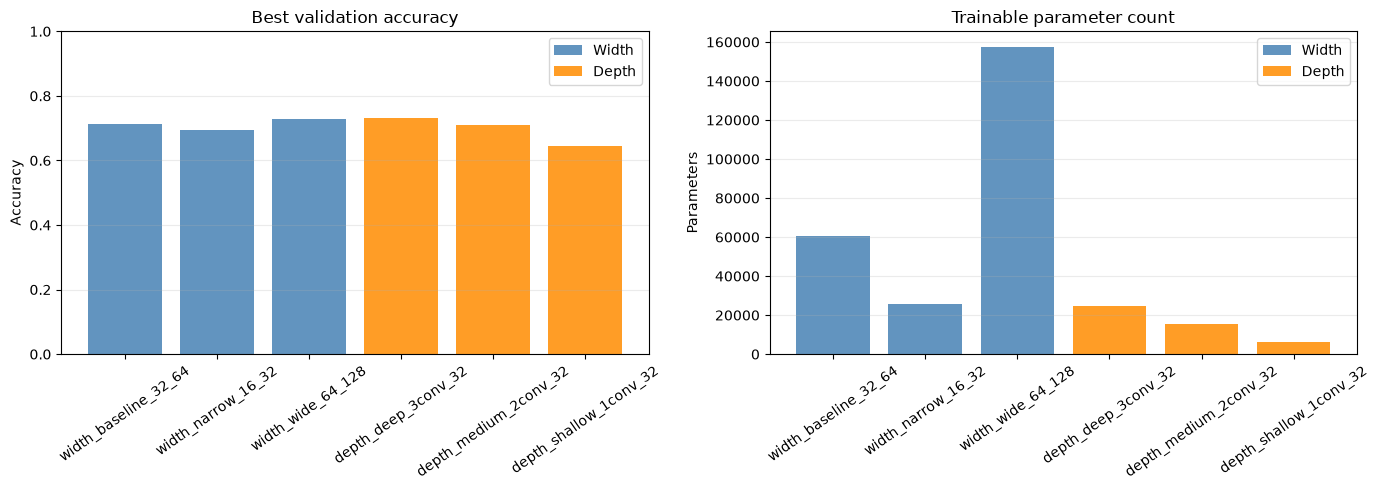

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for group, color in (("width", "steelblue"), ("depth", "darkorange")):
    rows = comparison[comparison["group"] == group]
    axes[0].bar(rows["name"], rows["best_val_accuracy"], label=group.title(), alpha=0.85, color=color)
    axes[1].bar(rows["name"], rows["trainable_parameters"], label=group.title(), alpha=0.85, color=color)
axes[0].set(title="Best validation accuracy", ylabel="Accuracy", ylim=(0, 1))
axes[1].set(title="Trainable parameter count", ylabel="Parameters")
for ax in axes:
    ax.tick_params(axis="x", labelrotation=35)
    ax.grid(axis="y", alpha=0.25)
    ax.legend()
fig.tight_layout()
fig.savefig(ARTIFACT_DIR / "width_depth_comparison.png", dpi=160, bbox_inches="tight")
plt.show()


## 12. Discussion and conclusion

### Effect of width

All three width configurations use two convolutional layers and the same training settings. Increasing the filters from 16/32 to 32/64 raised the parameter count from 25,578 to 60,362 and the best validation accuracy from 69.34% (epoch 12) to 71.44% (epoch 6). The 64/128 model reached 72.92% (epoch 6) with 157,578 parameters. The baseline-to-wide increase added 97,216 parameters for a 1.48 percentage points gain in best validation accuracy.

Training accuracy rose with width, reaching 79.68%, 90.88%, and 95.05% for narrow, baseline-width, and wide models. Their final validation accuracies were 67.80%, 67.86%, and 70.02%. The growing gap, especially for the wide model, and the decline from peak validation accuracy by epoch 20 indicate that the larger models fit the training set more closely without a matching late-epoch validation improvement.

### Effect of depth

The shallow, medium, and deep models reached best validation accuracies of 64.48% (epoch 20), 70.92% (epoch 18), and 73.30% (epoch 17). Their parameter counts were 6,026, 15,274, and 24,522. In these runs, adding a second convolutional block improved the best validation accuracy by 6.44 percentage points; the third block added a further 2.38 percentage points.

This depth comparison changes pooling as well as convolution count: each convolution is followed by max pooling, and adaptive average pooling then produces the classifier input. The deeper networks therefore downsample the image more times before the classifier. The results compare the complete architectures tested, and do not isolate the effect of convolutional depth alone.

### Interpretation and limitations

The deep model had the highest observed best validation accuracy (73.30%), 0.38 percentage points above the wide model. This is an outcome on the shared validation split, not proof that it is the best model overall. The validation set was used to compare configurations and select each model's best epoch; the official CIFAR-10 test set was not loaded or evaluated in Exercise 4.

These results come from one fixed seed and one train/validation split, with no data augmentation or learning-rate schedule and a fixed 20-epoch budget. Repeating the comparisons across independent splits or seeds would show how stable the observed differences are. The pooling difference in the depth experiment should also be considered when interpreting its apparent gains.

### Conclusion

Within these six runs, increasing width improved best validation accuracy, but the gains became smaller as parameter counts grew and the larger models showed wider final training-to-validation gaps. Increasing depth also improved validation accuracy in the tested architectures, although pooling changes mean that this is not a depth-only comparison. The deep configuration recorded the highest validation result, but it should be treated as the strongest result on this validation split rather than a definitive overall winner. No Exercise 4 test-set result is reported.